# Data Preparation

The following code block first reads the VCQ data from its CSV file into the `raw_df` DataFrame object. It then creates the demo_df object to contain only the columns for demographic questions. In addition, it removes the prefix 'demo_' from all column names in demo_df.

Review the [VCQ code book](https://docs.google.com/document/d/1uYfUuUsPVQyD3puVvbIMjamYuVPr_f4gtJuSB5Wj-WA/edit) as needed.

In [ ]:
# Collect data into a DataFrame object
import pandas as pd
raw_df = pd.read_csv('https://raw.githubusercontent.com/qarnac/cs201/main/vcq_data_nan.csv')

# Create a new DataFrame object to holds only demographic data
demo_df = raw_df.filter(regex='^demo').copy()
# Remove the 'demo_' prefix from column names
demo_df.columns = demo_df.columns.str.removeprefix('demo_')
# Replace 1 with 'Yes' and 2 with 'No' for related columns
yes_no_map = {1:'Yes', 2:'No'}
yes_no_columns = ['children', 'employed01', 'employed02', 'employed04']
demo_df[yes_no_columns] = demo_df[yes_no_columns].replace(yes_no_map)
demo_df.head()

,gender,age,relationshipstatus01,children,classstanding,units,gpa,employed01,employed02,employed03,incomehousehold,incomepersonal,politics,religion,relationshipstatus02,employed04
0,1,19.0,1,No,Sophomore,15.0,3.15,Yes,Yes,45.0,60000.0,16000.0,NaN,6.0,1.0,Yes
1,2,26.0,2,No,Junior,14.0,3.30,Yes,Yes,35.0,27000.0,27000.0,4.0,5.0,2.0,Yes
2,1,NaN,1,No,Junior,15.0,3.11,No,No,NaN,6000.0,2000.0,4.0,3.0,1.0,NaN
3,2,NaN,1,No,Sophomore,17.0,3.40,No,No,NaN,NaN,NaN,3.0,4.0,1.0,No
4,2,19.0,1,No,Sophomore,13.0,3.00,No,No,NaN,NaN,NaN,3.0,3.0,1.0,No


# The unique and value_counts functions

To explore a column before cleaning it, pandas provides two helpful functions:
*  The unique() method shows all distinct values in a column
*  The value_counts() displays the frequency of each value.

In [ ]:
demo_df['children'].unique()

array(['No', 'Yes', nan], dtype=object)

The above result shows that the 'children' column contains three unique values: 'Yes', 'No', and nan. In Python, nan stands for "Not a Number". It represent underfined, unpresentable, or missing numeric data.

In [ ]:
demo_df['children'].value_counts()

,count
children,
No,495
Yes,47


The above result shows that 495 students responded No and only 47 students responded Yes for having children. There's no information on the number of nan values for this column. But since we know the total number of students is 543, we know that only one student did not answer this question.

## Practice

Use the unique and value_counts functions to explore categorical columns of your choice. You may use as many or as few code blocks as you'd like.

In [ ]:
# data exploration


**Add a text block** to share your findings about the categorical columns you chose to explore with the above code block(s). For example,

*  How many students responded each category?
*  Did every student answer this question? If not, how many didn't answer?

# Bar Chart

Earlier, we used the pandas' `plot` function to work with DataFrame objects. We can also use the `plot` function to work with Series too.

For example, the following code block shows how to use the plot function to set up a bar chart:

*  The `kind` parameter is set to `'bar'`, indicating a **bar chart** is to be created.
*  We do not have to specify x or y parameters since each Series only has one column.
*  The `figsize` parameter helps set the figure size as in `plt.figure` function.


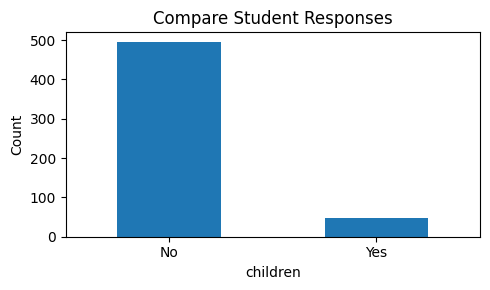

In [ ]:
import matplotlib.pyplot as plt     # import appropriate library

# Save the result of value_counts
children_counts = demo_df['children'].value_counts()

# create the bar chart
children_counts.plot(kind='bar',        # to create a bar chart
              figsize=(5, 3),           # 500 pixels for the width, 300 pixels for the height
              title='Compare Student Responses',     # title of the graph
              ylabel='Count',           # label for the y-axis
              rot=0                     # Rotation of the x-ticks values
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart


From this visualization, it is easy for us to see that there are much more students answering No than students answering Yes.

## Practice

Create bar charts to visualize different responses for categorical columns of your choice. You may use as many or as few code blocks as you'd like.

In [ ]:
# visualization


**Add a text block** to share your findings about the categorical columns you chose to explore with the above code block(s). For example,

*  How many students responded each category?
*  Did every student answer this question? If not, how many didn't answer?

# The cut function

This is also a skill we learned before. We can set up related labels and bin boundaries to classify values of a numeric column into categorical values. Here is a quick example for review.

In [ ]:
units_labels = ['Part Time', 'Full Time', 'Overload']
units_bins = [0, 9, 17, 30]
demo_df['units_category'] = pd.cut(demo_df['units'],
                                 labels = units_labels,
                                 bins = units_bins,
                                 right=True)
demo_df[['units', 'units_category']].tail()

,units,units_category
538,12.0,Full Time
539,15.0,Full Time
540,14.0,Full Time
541,20.0,Overload
542,12.0,Full Time


Again, we can use the value_counts() and plot function to create a bar chart comparing the number of students in different categories.

<Axes: title={'center': 'Status Comparisons'}, xlabel='units_category'>

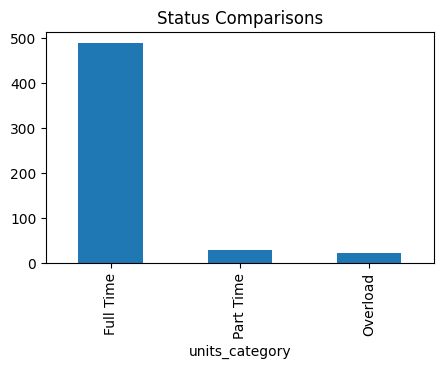

In [ ]:
import matplotlib.pyplot as plt

status_counts = demo_df['units_category'].value_counts()
status_counts.plot(kind='bar',
                   figsize=(5,3),
                   title='Status Comparisons')


## Practice

Create a new column to classify the values in gpa columns into bad, good, amazing. Then create a bar chart to visually compare the number of students in each category. You may use as many or as few code blocks as you'd like.

In [ ]:
# code block


Add a Markdown text block to explain what the bar chart tells you about students' gpa.

# Histograms

A **histogram** is a also a visualization that can help show how many values fall into different ranges (called bins).

Here's a reminder of some parameters for the plot function we can adjust.
*  The `kind` parameter specifies the type of chart is histogram.
*  The `y` parameter specifies the columns whose values will be counted according to the bins.
*  The `figsize` parameter specifies the width and height of the chart.
*  The `title` parameter specifies the title of the chart.
*  The `ylabel` parameter specifies the label for the y-axis.
*  The `bins` parameter specifies the number of bins to be used.
*  The `range` parameter specifies the lower and upper bounds of the bins.
*  The `color` parameter specifies the color of the bars.
*  The `edgecolor` parameter specifies the color of the edges for the bars.
*  The `alpha` parameter specifies the level of transparency for the bars. 0 is fully transparent and 1 is fully opaque.
*  The `legend` parameter indicates whether to show the legend of the graph.


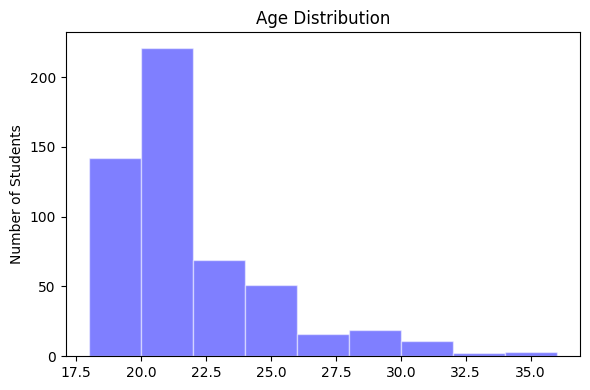

In [ ]:
import matplotlib.pyplot as plt     # import appropriate library

# create the bar chart
demo_df.plot(kind='hist',
        y='age',
        figsize=(6, 4),
        title='Age Distribution',
        ylabel='Number of Students',
        bins=9,              # The number of bins to be used for counting
        range=(18, 36),       # Smallest value is 75, largest value is 99
        color='blue',         # color of the bars
        edgecolor='white',    # color of the edges
        alpha=0.5,            # transparency of the bars
        legend=False
)

plt.tight_layout()                  # adjust spacing to avoid overlap
plt.show()                          # show the chart

From the above histogram, we can see that

*  There're close to 150 students younger than 20.
*  There're very few students 32 and older.
*  The largest age group is 20 and 21 years old.

## Practice

Call the describe function to find out the range and standard deviation for the gpa column of the dataset and then create a histogram to visualize the distribution of gpa. You may use as many/few code blocks as you'd like.

In [ ]:
# code block


Add a **Markdown text block** to explain what you learn about gpa distribution from the above histogram. For example

*  What are the boundary values for the leftmost bin? How many students fall into it?
*  What are the boundary values for the rightmost bin? How many students fall into it?
*  Pick one bin that is the tallest. What are the boundary values for the bin? How many students fall in that bin?
*  Pick one bin that is the shortest. What are the boundary values for the bin? How many students fall in that bin?